# 06 - Model Explainability (SHAP)

## Objective
Explain the selected model at two levels: globally (which features drive the book)
and individually (why *this* applicant received *this* probability). Every number
below comes from computed SHAP values -- nothing is written by hand.

SHAP values are additive contributions in log-odds space: positive pushes the
applicant towards default, negative away from it.

In [1]:
import sys
from pathlib import Path

# Make `src` importable when the notebook is run from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import pandas as pd

from src import config
from src.data import preprocessing
from src.features.engineering import add_credit_risk_features
from src.models import explain as E
from src.models import train as T

%matplotlib inline

## Configuration and data loading

In [3]:
SAMPLE_SIZE = 2000
raw = preprocessing.load_raw_data()
TARGET = preprocessing.detect_target(raw)
clean, _ = preprocessing.clean_data(raw, TARGET)
df = add_credit_risk_features(clean)
splits = T.split_data(df, TARGET)
model = T.load_model()          # saved by run_pipeline.py / notebook 05
model.named_steps["classifier"]

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='aucpr', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=2, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=400,
              n_jobs=-1, num_parallel_tree=None, ...)

## Building the explainer

In [4]:
sample = splits["X_test"].sample(min(SAMPLE_SIZE, len(splits["X_test"])),
                                 random_state=config.RANDOM_STATE)
explainer, transformed = E.build_explainer(model, sample)
shap_values = E.compute_shap_values(explainer, transformed)
shap_values.shape

(2000, 49)

## Global feature importance

In [5]:
importance = E.global_importance(shap_values, transformed)
importance.head(15)

,feature,mean_abs_shap,mean_shap
0,loan_to_income_ratio,0.552688,0.029396
1,person_income,0.530378,-0.093360
2,loan_int_rate,0.454819,-0.194259
3,person_home_ownership_OWN,0.358118,-0.153138
4,person_home_ownership_RENT,0.335858,-0.021689
5,loan_grade_D,0.309957,-0.038594
6,loan_intent_VENTURE,0.240795,-0.035453
7,loan_grade_A,0.232275,-0.067009
8,loan_percent_income,0.193981,-0.064566
9,payment_to_income,0.191004,-0.036110


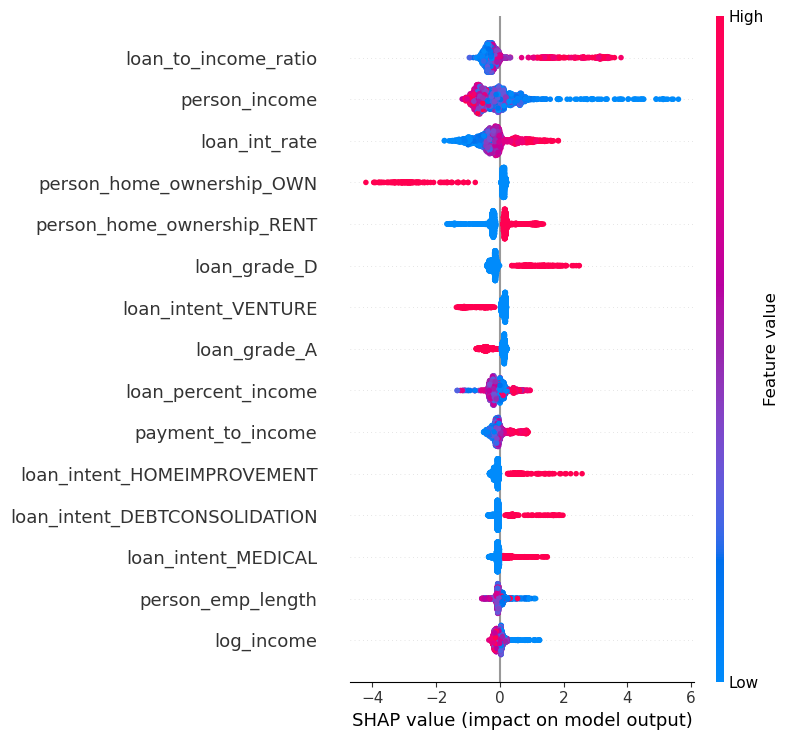

In [6]:
E.save_summary_plots(shap_values, transformed)
import shap
shap.summary_plot(shap_values, transformed, max_display=15)

The beeswarm shows both magnitude and direction: for each feature, points to the
right increase predicted risk, and the colour shows whether that came from a high
or a low feature value.

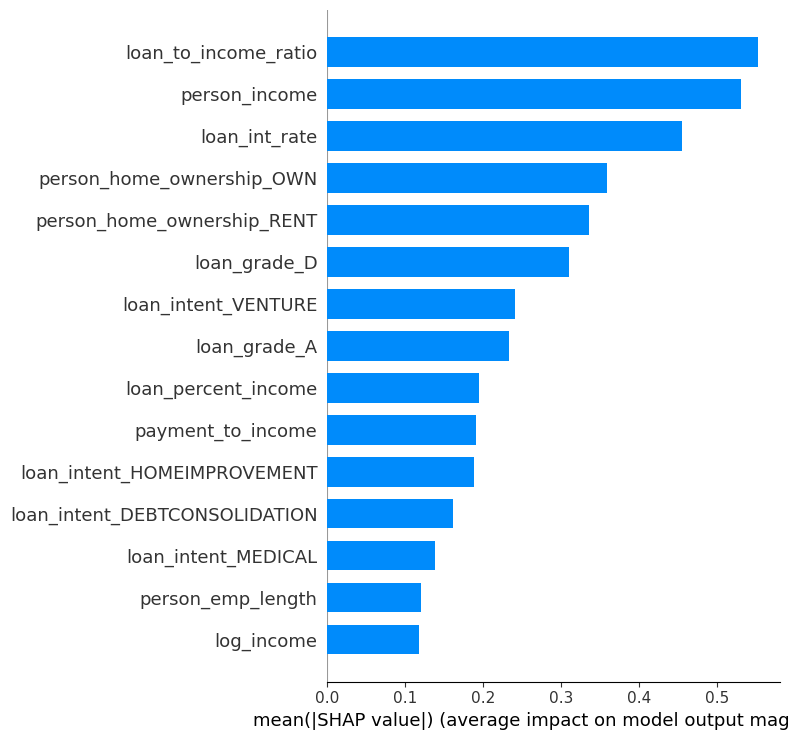

In [7]:
shap.summary_plot(shap_values, transformed, plot_type="bar", max_display=15)

## Individual prediction explanations

In [8]:
scored_sample = sample.copy()
scored_sample["pd"] = model.predict_proba(sample)[:, 1]
riskiest = scored_sample["pd"].idxmax()
safest = scored_sample["pd"].idxmin()
scored_sample.loc[[riskiest, safest], ["person_income", "loan_amnt", "loan_grade",
                                       "loan_int_rate", "loan_percent_income", "pd"]]

,person_income,loan_amnt,loan_grade,loan_int_rate,loan_percent_income,pd
23070,16000.0,5000,E,16.45,0.31,0.999920
15429,135000.0,16000,A,6.91,0.12,0.000074


In [9]:
for label, index in [("HIGHEST predicted risk", riskiest), ("LOWEST predicted risk", safest)]:
    customer = sample.loc[[index]]
    explanation = E.explain_customer(model, explainer, customer)
    print(f"=== {label} | PD = {model.predict_proba(customer)[0, 1]:.4f} ===")
    for line in E.narrate_contributions(explanation):
        print(" -", line)
    print()

=== HIGHEST predicted risk | PD = 0.9999 ===
 - person_income increased predicted default risk (SHAP +2.363)
 - loan_to_income_ratio increased predicted default risk (SHAP +2.016)
 - loan_grade_E increased predicted default risk (SHAP +1.174)
 - loan_intent_DEBTCONSOLIDATION increased predicted default risk (SHAP +0.877)
 - person_home_ownership_RENT increased predicted default risk (SHAP +0.727)
 - loan_grade_D reduced predicted default risk (SHAP -0.147)
 - loan_intent_HOMEIMPROVEMENT reduced predicted default risk (SHAP -0.079)
 - loan_intent_MEDICAL reduced predicted default risk (SHAP -0.032)
 - est_monthly_payment reduced predicted default risk (SHAP -0.014)
 - loan_grade_F reduced predicted default risk (SHAP -0.013)

=== LOWEST predicted risk | PD = 0.0001 ===
 - employment_stability increased predicted default risk (SHAP +0.205)
 - loan_grade_B increased predicted default risk (SHAP +0.089)
 - person_home_ownership_MORTGAGE increased predicted default risk (SHAP +0.034)
 - per

In [10]:
explanation = E.explain_customer(model, explainer, sample.loc[[riskiest]], top_n=8)
pd.DataFrame(explanation["increases_risk"])

,feature,shap_value,feature_value
0,person_income,2.3629,16000.0000
1,loan_to_income_ratio,2.0156,0.3125
2,loan_grade_E,1.1743,1.0000
3,loan_intent_DEBTCONSOLIDATION,0.8766,1.0000
4,person_home_ownership_RENT,0.7268,1.0000
5,loan_percent_income,0.6288,0.3100
6,payment_to_income,0.5758,0.0921
7,loan_int_rate,0.5715,16.4500


In [11]:
pd.DataFrame(explanation["decreases_risk"])

,feature,shap_value,feature_value
0,loan_grade_D,-0.1469,0.000
1,loan_intent_HOMEIMPROVEMENT,-0.0789,0.000
2,loan_intent_MEDICAL,-0.0322,0.000
3,est_monthly_payment,-0.0136,122.789
4,loan_grade_F,-0.0135,0.000
5,income_group_30k-60k,-0.0129,0.000
6,loan_grade_G,-0.0078,0.000
7,loan_amount_group_15k-25k,-0.0025,0.000


## Contribution chart for a single applicant

In [12]:
import matplotlib.pyplot as plt

contributions = (pd.DataFrame(explanation["increases_risk"] + explanation["decreases_risk"])
                 .drop_duplicates("feature")
                 .sort_values("shap_value"))
colours = ["#C0392B" if value > 0 else "#2E8B57" for value in contributions["shap_value"]]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(contributions["feature"], contributions["shap_value"], color=colours)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("SHAP value (log-odds contribution to default)")
ax.set_title(f"Drivers for the highest-risk applicant "
             f"(PD = {model.predict_proba(sample.loc[[riskiest]])[0, 1]:.3f})")
fig.tight_layout()

## Results
The ranked table and the plots above are the actual SHAP output; `run_pipeline.py`
writes the same ranking to `reports/shap_global_importance.csv`.

## Interpretation
Explanations are stated in terms of the transformed feature space (one-hot columns
included), which is what the model actually consumes. When reporting back to a
credit officer, translate each contribution into the applicant's own attribute --
for example, a large positive contribution on the loan-to-income ratio means the
requested amount is high relative to income.

## Caveat
SHAP explains the *model*, not the world. These are associations learned from
historical decisions, not causal effects, and `loan_grade` / `loan_int_rate` carry
the lender's prior risk assessment. Any production use needs fairness testing
across protected groups and human review of adverse decisions.

## Conclusion
The model's drivers match the EDA and the SQL analytics, so its behaviour is
defensible to a risk committee -- the final requirement before serving it through
the API and dashboard.